### Imports

In [2]:
from mpqp import *
from mpqp.execution import run, IBMDevice
import numpy as np
from scipy.linalg import expm

### General function to encode a qubit state from an array

In [ ]:
def encode_vector(b_vector):

    qc = QCircuit()

    b_normalized = b_vector / np.linalg.norm(b_vector)

    theta = 2 * np.arccos(b_normalized[0])

    qc.add([
        Ry(theta, 3),
        Barrier()
    ])

    return qc

### Definition of the QPE and IQPE circuits

In [ ]:
def qpe(A, t, clock_qubits, b_qubits):
    qc = QCircuit()

    for q in clock_qubits:
        qc.add(H(q))

    for i, q in enumerate(clock_qubits):
        U = expm(1j * A * t * (2 ** i))
        U_gate = CustomGate(U, b_qubits)
        qc.add(CustomControlledGate(q, U_gate))

    qc.add(Barrier())

    # IQFT
    qc.add([
        H(clock_qubits[-1]),
        CRk_dagger(2, clock_qubits[-1], clock_qubits[-2]),
        H(clock_qubits[-2]),
        SWAP(clock_qubits[-2], clock_qubits[-1]),
        Barrier()
    ])

    return qc

def iqpe(A, t, clock_qubits, b_qubits):
    qc = QCircuit()

    qc.add([
        SWAP(clock_qubits[-2], clock_qubits[-1]),
        H(clock_qubits[-2]),
        CRk(2, clock_qubits[-1], clock_qubits[-2]),
        H(clock_qubits[-1]),
        Barrier()
    ])

    for i, q in reversed(list(enumerate(clock_qubits))):
        U_inv = expm(-1j * A * t * (2 ** i))
        U_inv_gate = CustomGate(U_inv, b_qubits)
        qc.add(CustomControlledGate(q, U_inv_gate))

    for q in clock_qubits:
        qc.add(H(q))

    qc.add(Barrier())

    return qc

### Function that inverse the eigenvalue

In [ ]:
def eigenvalue_inversion(clock_qubits, ancilla_qubit):
    qc = QCircuit()

    nb_clock_qubits = len(clock_qubits)

    for i, q in enumerate(clock_qubits):
        angle = 2 * np.arcsin(1 / (2**(nb_clock_qubits - 1 - i)))
        qc.add(CustomControlledGate(q, Ry(angle, ancilla_qubit)))

    qc.add(Barrier())
    return qc

# HHL Algorithm

In [ ]:
def hhl(A, b, t):
    qc = QCircuit()

    ### Encoding |b> ###

    encoding_qc = encode_vector(b)
    qc.append(encoding_qc)

    ### Applying QPE for our matrix ###

    qpe_qc = qpe(A, t, clock_qubits=[1, 2], b_qubits=[3])
    qc.append(qpe_qc)

    ### Eigenvalue inversion ###

    inversion_qc = eigenvalue_inversion(clock_qubits=[1,2], ancilla_qubit=0)
    qc.append(inversion_qc)

    ### Applying IQPE for our matrix ###

    iqpe_qc = iqpe(A, t, clock_qubits=[1, 2], b_qubits=[3])
    qc.append(iqpe_qc)

    ### Measurement ###

    qc.add(BasisMeasure(shots=8192))

    return qc


# TESTS

Result: IBMDevice, AER_SIMULATOR_STATEVECTOR
  Counts: [1523, 1461, 0, 0, 0, 0, 0, 0, 500, 4708, 0, 0, 0, 0, 0, 0]
  Probabilities: [0.18591, 0.17834, 0, 0, 0, 0, 0, 0, 0.06104, 0.57471, 0, 0, 0, 0, 0, 0]
  Samples:
    State: 0000, Index: 0, Count: 1523, Probability: 0.1859131
    State: 0001, Index: 1, Count: 1461, Probability: 0.1783447
    State: 1000, Index: 8, Count: 500, Probability: 0.0610352
    State: 1001, Index: 9, Count: 4708, Probability: 0.574707
  Error: None


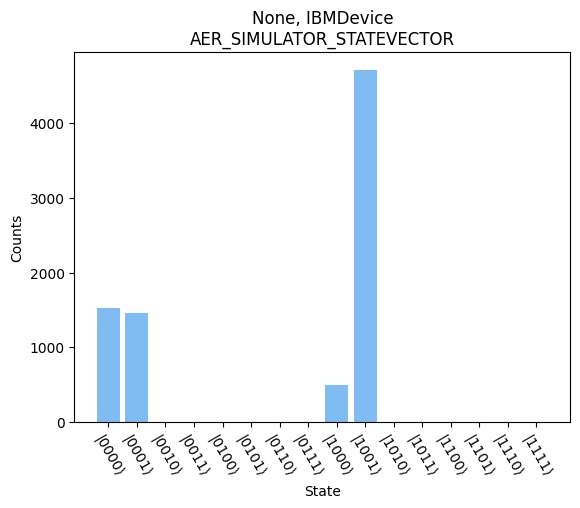

 ===> 0.10620220900594732 ~ 0.1111111111111111
Result: IBMDevice, AER_SIMULATOR_STATEVECTOR
  Counts: [0, 0, 0, 0, 0, 0, 0, 0, 0, 8192, 0, 0, 0, 0, 0, 0]
  Probabilities: [0, 0, 0, 0, 0, 0, 0, 0, 0, 1, 0, 0, 0, 0, 0, 0]
  Samples:
    State: 1001, Index: 9, Count: 8192, Probability: 1
  Error: None


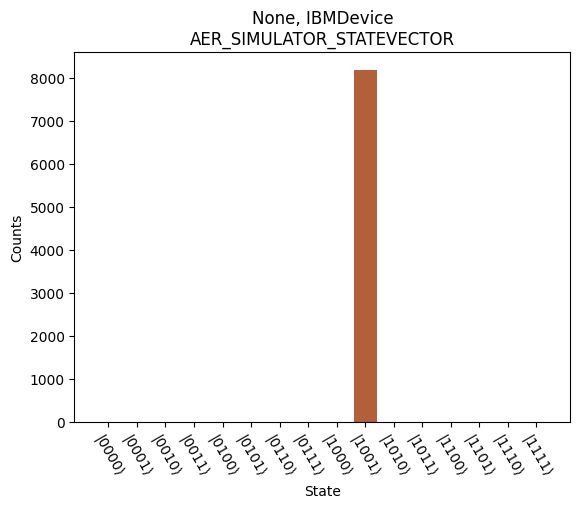

 ===> 1.0 = 1.0
Result: IBMDevice, AER_SIMULATOR_STATEVECTOR
  Counts: [1483, 1573, 0, 0, 0, 0, 0, 0, 4639, 497, 0, 0, 0, 0, 0, 0]
  Probabilities: [0.18103, 0.19202, 0, 0, 0, 0, 0, 0, 0.56628, 0.06067, 0, 0, 0, 0, 0, 0]
  Samples:
    State: 0000, Index: 0, Count: 1483, Probability: 0.1810303
    State: 0001, Index: 1, Count: 1573, Probability: 0.1920166
    State: 1000, Index: 8, Count: 4639, Probability: 0.5662842
    State: 1001, Index: 9, Count: 497, Probability: 0.0606689
  Error: None


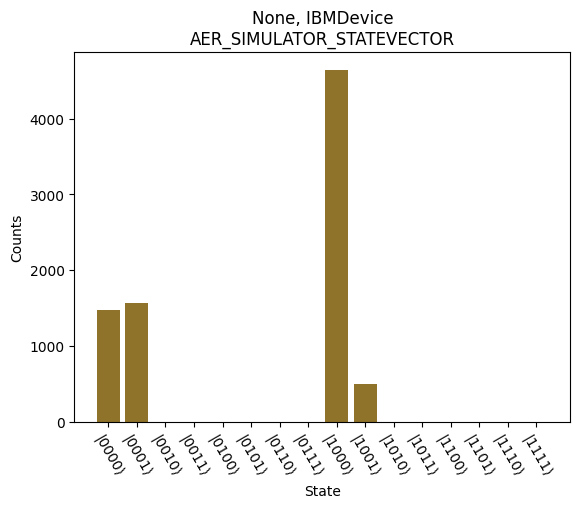

 ===> 9.33400402414487 ~ 9.0


In [ ]:
##############
### TEST 1 ###
##############

A = np.array([[1, -1/3], [-1/3, 1]])
b = np.array([0, 1])
t = 3 * np.pi / 4
# x = [3/8, 9/8]

hhl_qc = hhl(A, b, t)

result = run(hhl_qc, IBMDevice.AER_SIMULATOR_STATEVECTOR)
print(result)
result.plot()

for sample in result.samples:
  if sample.bin_str == "1000":
    state_1000 = sample.probability
  elif sample.bin_str == "1001":
    state_1001 = sample.probability

print(" ===>", state_1000 / state_1001, '~', 1 / 9)

##############
### TEST 2 ###
##############

A = np.array([[1, 0], [0, 2]])
b = np.array([0, 1])
t = np.pi / 2
# x = [0, 1]

hhl_qc = hhl(A, b, t)

result = run(hhl_qc, IBMDevice.AER_SIMULATOR_STATEVECTOR)
print(result)
result.plot()

for sample in result.samples:
  if sample.bin_str == "1001":
    print(" ===>", sample.probability , '=', 1.0)

##############
### TEST 3 ###
##############

A = np.array([[3/2, -1/2], [-1/2, 3/2]])
b = np.array([1, 0])
t = np.pi / 2
# x = [3/4, 1/4]

hhl_qc = hhl(A, b, t)

result = run(hhl_qc, IBMDevice.AER_SIMULATOR_STATEVECTOR)
print(result)
result.plot()

for sample in result.samples:
  if sample.bin_str == "1000":
    state_1000 = sample.probability
  elif sample.bin_str == "1001":
    state_1001 = sample.probability

print(" ===>", state_1000 / state_1001, '~', 9.0)

# res_exp = run(hhl_qc, IBMDevice.AER_SIMULATOR)
# print("Espérance mesurée :", res_exp.expectation_values['observable_0'] / res_exp.expectation_values['observable_1'])


In [ ]:
def hhl_statevector(A, b, t):
    qc = QCircuit()

    qc.append(encode_vector(b))
    qc.append(qpe(A, t, clock_qubits=[1, 2], b_qubits=[3]))
    qc.append(eigenvalue_inversion(clock_qubits=[1, 2], ancilla_qubit=0))
    qc.append(iqpe(A, t, clock_qubits=[1, 2], b_qubits=[3]))

    return qc

In [ ]:
A = np.array([[3/2, -1/2], [-1/2, 3/2]])
b = np.array([1, 0])
t = np.pi / 2
# x = [3/4, 1/4]

hhl_qc = hhl_statevector(A, b, t)
result = run(hhl_qc, IBMDevice.AER_SIMULATOR_STATEVECTOR)

state = result.state_vector
print(state)

  State vector: [0.43301, 0.43301, 0, 0, 0, 0, 0, 0, 0.75, -0.25, 0, 0, 0, 0, 0, 0]
  Probabilities: [0.1875, 0.1875, 0, 0, 0, 0, 0, 0, 0.5625, 0.0625, 0, 0, 0, 0, 0, 0]
  Number of qubits: 4


In [ ]:
alpha_1000 = np.abs(state.vector[8]) # |1000>
alpha_1001 = np.abs(state.vector[9]) # |1001>

x_hhl = np.array([alpha_1000, alpha_1001])
print(x_hhl)
x_hhl = x_hhl / np.linalg.norm(x_hhl)
print(x_hhl)

[0.75 0.25]
[0.9486833  0.31622777]
